# Case 8 - Why is electricity expensive in Romania? A data-based, non-causal decomposition

Energy MBA - Energy Markets Quantitative Analysis (EMQA) - Prof. Daniel Traian Pele

Bucharest University of Economic Studies - Romanian Academy, Institute for Economic Forecasting

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "en"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Case study (not built on a paper).** This notebook documents, on the course data and on Eurostat retail prices, *how much* more expensive
Romanian electricity is than in Hungary, Bulgaria, Germany and the EU, *when* (hour of day, year) and *with which observable factors* the premium is associated.

**What we do.** (1) The facts: day-ahead (PZU, *Piața pentru Ziua Următoare*, run by OPCOM) prices for RO, HU, BG and DE-LU, 2019 - October 2026, annual, monthly and by hour of day;
Eurostat household and non-household retail prices and their components. (2) The candidate drivers: the evening deficit and imports, hydro, nuclear availability,
the short-run marginal cost (SRMC) of a gas plant, coupling and congestion, the coal decline. (3) A simple daily regression with HAC
(heteroskedasticity- and autocorrelation-consistent) standard errors and an *accounting* decomposition of the change in the mean price between Jan-Oct 2024 and Jan-Oct 2026.

**What we do not do.** No causal claim is made. The drivers are correlated with each other and partly with the price itself (imports and reservoir hydro respond to price).
The decomposition is a description of co-movements, not an estimate of what would have happened under another policy.

**Related work of our group (pointers only).** Andrei, Pele & Cramer (2026), PICBE 20(1), doi:10.2478/picbe-2026-0013 (the 2024 crisis, Case 1);
Proșcanu, Proșcanu & Pele (2025), JSES 14(2), doi:10.2478/jses-2025-0009 (price elasticity of demand, Case 5);
Andrei et al. (2026), SSRN 6872381, doi:10.2139/ssrn.6872381 (battery arbitrage, Case 6).

## 0. Settings and helpers

In [2]:
import json, datetime, re, urllib.request
import statsmodels.api as sm

END = "2026-10-31"                 # last full month of data used in the case
YEARS = list(range(2019, 2027))    # 2026 = January-October
ETA = 0.50                         # assumed electrical efficiency of the marginal gas plant (CCGT/OCGT mix)
ETA_LO, ETA_HI = 0.40, 0.58        # sensitivity band: old open-cycle unit vs modern combined-cycle unit
EF_TH = 0.202                      # tCO2 per MWh of gas burnt (thermal), IPCC default for natural gas
REG_START = "2023-01-01"         # start of the regression sample (chronological, in-sample)
HAC_LAGS = 7                       # Newey-West lags (days)
NUC_OFF, NUC_ONE = 50, 900         # MW thresholds: below NUC_OFF no unit, below NUC_ONE one unit
EVE = [18, 19, 20, 21]             # evening hours 18:00-22:00, local time
MID = [10, 11, 12, 13, 14, 15]     # midday hours 10:00-16:00, local time
NAME = {"RO": ("Romania", "România"), "HU": ("Hungary", "Ungaria"), "BG": ("Bulgaria", "Bulgaria"),
        "DE_LU": ("Germany-Lux.", "Germania-Lux."), "DE": ("Germany", "Germania"), "PL": ("Poland", "Polonia"),
        "EU27_2020": ("EU-27", "UE-27")}
nm = lambda z, lang: cu.T(lang, *NAME[z])
SRC_ES = {"en": "Eurostat", "ro": "Eurostat"}

# ---- Eurostat retail prices: downloaded once from the public dissemination API and cached in data_eurostat/
ES_API = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/"
ES_GEO = ["RO", "HU", "BG", "PL", "DE", "EU27_2020"]
ES_DIR = "data_eurostat"
def es_url(ds, cur):
    return ES_API + ds + "?format=JSON&lang=EN&" + "&".join("geo=" + g for g in ES_GEO) + "&currency=" + cur

def eurostat(ds, cur="EUR"):
    """Return a tidy DataFrame of a Eurostat dataset (JSON-stat 2.0), using the local cache if present."""
    os.makedirs(ES_DIR, exist_ok=True)
    path, logp = os.path.join(ES_DIR, f"{ds}_{cur}.json"), os.path.join(ES_DIR, "download_log.json")
    log = json.load(open(logp)) if os.path.exists(logp) else {}
    if not os.path.exists(path):
        url = es_url(ds, cur)
        with urllib.request.urlopen(url, timeout=180) as r:
            raw = r.read()
        open(path, "wb").write(raw)
        log[os.path.basename(path)] = {"url": url, "downloaded": datetime.date.today().isoformat(),
                                       "eurostat_updated": json.loads(raw)["updated"]}
        json.dump(log, open(logp, "w"), indent=1)
    j = json.load(open(path))
    ids, size = j["id"], j["size"]
    cats = []
    for dname in ids:
        idx = j["dimension"][dname]["category"]["index"]
        cats.append(sorted(idx, key=idx.get) if isinstance(idx, dict) else idx)
    rows = []
    for k, v in j["value"].items():
        k, pos = int(k), []
        for s in reversed(size):
            pos.append(k % s); k //= s
        rows.append([cats[i][p] for i, p in enumerate(pos[::-1])] + [v])
    return pd.DataFrame(rows, columns=ids + ["value"])

def big(lang):
    """Slightly larger fonts for half-width charts in the brief."""
    return plt.rc_context({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12, "legend.fontsize": 11,
                           "xtick.labelsize": 11, "ytick.labelsize": 11})

## 1. Data

In [3]:
pd_ = cu.prices_daily().loc["2015-01-01":END, ["RO", "HU", "BG", "DE_LU"]]
ph = cu.prices_hourly().loc["2019-01-01":END, ["RO", "HU", "BG", "DE_LU"]]
pn = pd.read_csv(os.path.join(cu.DATA, "power_da_prices_native_utc.csv"), parse_dates=["timestamp_utc"]).set_index("timestamp_utc")
pn = pn.loc["2019-01-01":END]                         # native MTU (60 min, 15 min from Oct 2025), UTC
gh = cu.generation_ro_hourly().loc["2015-01-01":END]
gd = cu.generation_ro_daily().loc["2015-01-01":END]
xh = cu.crossborder_ro_hourly().loc["2019-01-01":END]  # + = net import into Romania, MW
xd = cu.crossborder_ro_daily().loc["2015-01-01":END]
gbd = pd.read_csv(os.path.join(cu.DATA, "generation_bg_mw_daily_cet.csv"), parse_dates=["date_cet"]).set_index("date_cet").loc[:END]
ttf = cu.ttf_monthly().loc["2015-01-01":END, "ttf_eur_mwh"]
eua = cu.eua_daily()
# EUA: EEX primary-auction price where available (to Dec 2025), else the physically backed ETC proxy (covers 2026)
# the ETC is a security whose carbon entitlement shrinks with fees, so its price is not EUR/tCO2 one-for-one:
# rescale it by the mean auction/ETC price ratio over the last overlap year (2025) before splicing
_ov = eua.loc["2025", ["eua_eex_auction_eur_t", "eua_etc_co2l_eur_per_unit"]].dropna()
ETC_RATIO = float((_ov.eua_eex_auction_eur_t / _ov.eua_etc_co2l_eur_per_unit).mean())
LAST_AUCTION = eua["eua_eex_auction_eur_t"].dropna().index.max()
_auc = eua["eua_eex_auction_eur_t"].dropna()
_etc = eua["eua_etc_co2l_eur_per_unit"].dropna()
eua_d = pd.concat([_auc, _etc.loc[_etc.index > LAST_AUCTION] * ETC_RATIO]).sort_index().loc["2015-01-01":END]   # proxy only after the last auction
print("EUA proxy: ETC price x %.4f (mean auction/ETC ratio in 2025, %d overlapping days)" % (ETC_RATIO, len(_ov)))
eua_m = eua_d.resample("MS").mean()
gd["hydro"] = gd.hydro_run_of_river + gd.hydro_water_reservoir
gd["coal"] = gd.brown_coal_lignite.fillna(0) + gd.hard_coal.fillna(0)
gh["hydro"] = gh.hydro_run_of_river + gh.hydro_water_reservoir
yr = lambda s: s.groupby(s.index.year)
print("daily prices", pd_.index.min().date(), "-", pd_.index.max().date())
print("hourly generation", gh.index.min(), "-", gh.index.max())
print("TTF monthly to", ttf.index.max().date(), "| EUA to", eua_d.dropna().index.max().date())

EUA proxy: ETC price x 1.0320 (mean auction/ETC ratio in 2025, 211 overlapping days)
daily prices 2015-01-01 - 2026-10-31
hourly generation 2015-01-01 02:00:00+02:00 - 2026-10-31 23:00:00+02:00
TTF monthly to 2026-10-01 | EUA to 2026-10-30


## 2. The fact: wholesale prices

In [4]:
w = pd_.loc["2019-01-01":END]
ann = yr(w).mean()
ann["RO_HU"], ann["RO_BG"], ann["RO_DE"] = ann.RO - ann.HU, ann.RO - ann.BG, ann.RO - ann.DE_LU
hh = ph.copy()
hh["dDE"], hh["dHU"], hh["dBG"] = hh.RO - hh.DE_LU, hh.RO - hh.HU, hh.RO - hh.BG
eve = hh[hh.index.hour.isin(EVE)]; mid = hh[hh.index.hour.isin(MID)]
ann["eve_DE"] = yr(eve.dDE).mean(); ann["mid_DE"] = yr(mid.dDE).mean()
ann["eve_HU"] = yr(eve.dHU).mean()
print(ann.round(1))

tab = ann[["RO", "HU", "BG", "DE_LU", "RO_HU", "RO_BG", "RO_DE", "eve_DE", "mid_DE"]].copy()
tab.index = [(str(y) + ("*" if y == 2026 else ""), str(y) + ("*" if y == 2026 else "")) for y in tab.index]
cu.write_table(tab, "wholesale",
    header=[("Year", "Anul"), ("RO", "RO"), ("HU", "HU"), ("BG", "BG"), ("DE-LU", "DE-LU"),
            ("RO$-$HU", "RO$-$HU"), ("RO$-$BG", "RO$-$BG"), ("RO$-$DE", "RO$-$DE"),
            (f"RO$-$DE, {EVE[0]}--{EVE[-1] + 1}",) * 2, (f"RO$-$DE, {MID[0]}--{MID[-1] + 1}",) * 2], digits=1)

             RO     HU     BG  DE_LU  RO_HU  RO_BG  RO_DE  eve_DE  mid_DE  eve_HU
date_cet                                                                         
2019       50.4   50.4   47.5   37.7    0.1    2.9   12.7    18.8    16.1     1.6
2020       39.5   39.0   39.3   30.5    0.5    0.2    9.0    10.9    11.1     0.4
2021      111.4  113.8  108.7   96.8   -2.4    2.7   14.6    21.9    18.2    -0.7
2022      265.3  271.7  252.8  235.5   -6.4   12.5   29.8    50.5    38.5     2.5
2023      103.7  106.8  103.8   95.2   -3.1   -0.1    8.6    23.0     4.6     1.9
2024      103.5  100.8  102.5   78.5    2.7    1.0   25.0    63.7    11.3     6.0
2025      108.2  108.5  106.9   89.3   -0.3    1.3   18.8    43.3     7.3     1.2
2026      137.4  141.0  129.9  114.0   -3.5    7.6   23.4    42.9    10.5    -7.0


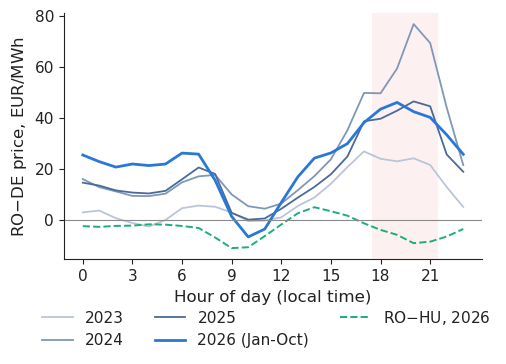

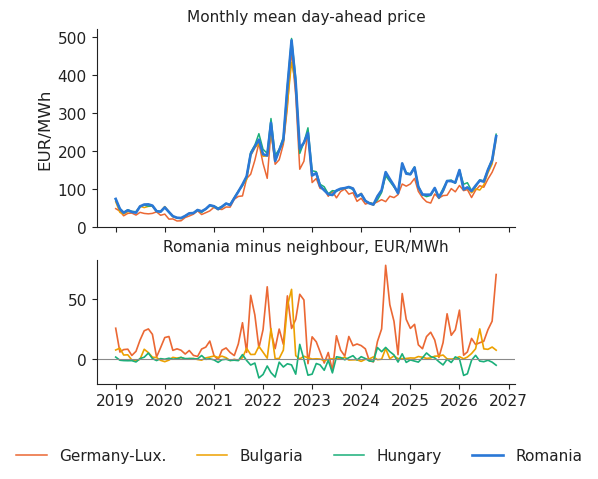

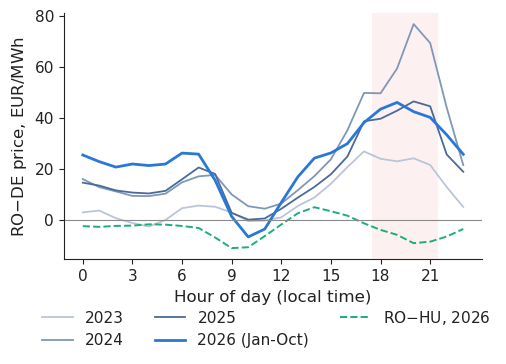

In [5]:
m = w.resample("MS").mean()
def fig_monthly(lang):
    with big(lang):
        fig, (ax, bx) = plt.subplots(2, 1, figsize=(5.4, 4.6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
        for z in ["DE_LU", "BG", "HU", "RO"]:
            ax.plot(m.index, m[z], color=cu.PAL[z], lw=1.9 if z == "RO" else 1.1, label=nm(z, lang))
        ax.set_ylabel(cu.T(lang, "EUR/MWh", "EUR/MWh")); ax.set_ylim(0, None)
        ax.set_title(cu.T(lang, "Monthly mean day-ahead price", "Prețul mediu lunar pentru ziua următoare"), fontsize=11)
        for z in ["DE_LU", "BG", "HU"]:
            bx.plot(m.index, m.RO - m[z], color=cu.PAL[z], lw=1.2)
        bx.axhline(0, color=cu.MUTED, lw=0.8)
        bx.set_title(cu.T(lang, "Romania minus neighbour, EUR/MWh", "România minus vecinul, EUR/MWh"), fontsize=11)
        cu.comma_axis(bx, lang)
        cu.legend_bottom(fig, ncol=4, y=0.0)
    return fig
cu.save_both(fig_monthly, "f1_monthly")

prem = hh.groupby([hh.index.year, hh.index.hour]).dDE.mean().unstack(0)
premHU = hh.groupby([hh.index.year, hh.index.hour]).dHU.mean().unstack(0)
def fig_prem(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        cols = {2023: "#b9c6d8", 2024: "#7f97b8", 2025: "#4a6a99", 2026: cu.PAL["RO"]}
        for y, c in cols.items():
            ax.plot(prem.index, prem[y], color=c, lw=2.0 if y == 2026 else 1.3,
                    label=str(y) + (cu.T(lang, " (Jan-Oct)", " (ian.–oct.)") if y == 2026 else ""))
        ax.plot(premHU.index, premHU[2026], color=cu.PAL["HU"], ls="--", lw=1.4, label=cu.T(lang, "RO$-$HU, 2026", "RO$-$HU, 2026"))
        ax.axhline(0, color=cu.MUTED, lw=0.8)
        ax.axvspan(17.5, 21.5, color=cu.EVENT, alpha=0.08, lw=0)
        ax.set_xticks(range(0, 24, 3)); ax.set_xlabel(cu.T(lang, "Hour of day (local time)", "Ora din zi (ora locală)"))
        ax.set_ylabel(cu.T(lang, "RO$-$DE price, EUR/MWh", "Diferența RO$-$DE, EUR/MWh"))
        cu.comma_axis(ax, lang)
        cu.legend_bottom(fig, ncol=3, y=0.0)
    return fig
cu.save_both(fig_prem, "f2_premium_by_hour")

**Read the charts.** Romania moves with Hungary and Bulgaria: the annual RO-HU difference is a few EUR/MWh, of either sign.
The premium that matters is against Germany, and it is concentrated in the evening hours (shaded), when it is several times the midday premium.
In 2026 the evening premium is no longer *Romanian*: RO is slightly cheaper than HU in the evening (dashed line). The evening problem is regional.

## 2b. The price chain: forward, balancing, import parity

Extra market data (downloaded by `download_c8_data.py` into `data_c8/`, with URL and date in `data_c8/download_log.json`):
* **Forward:** OPCOM ROPEX_FM, the volume-weighted price of all contracts *in delivery* in month M on the OPCOM forward markets
  (PCCB-LE, PCCB-NC, PC-OTC, PCSU, PMC, PCCB-LE-Flex), lei/MWh, converted to EUR at the ECB monthly average EUR/RON rate.
* **Balancing:** Transelectrica single final imbalance prices, 15-minute intervals, October 2023 - September 2026 (latest settlement run of each month).
  Blank cells of the published files are left missing.
* **Import parity:** under implicit day-ahead allocation the capacity is free when the interconnector is not congested; we therefore use the cheaper of the HU and BG day-ahead prices as the import-parity price
  and read RO prices above it as hours with a congested import border (the gap is the implicit congestion rent).

In [6]:
C8 = "data_c8"
fxr = pd.read_csv(os.path.join(C8, "ecb_eurron_monthly.csv")); fxr.index = pd.PeriodIndex(fxr.month, freq="M"); fxr = fxr.ron_per_eur
print(json.dumps({k: (v["http_status"], v["downloaded"]) for k, v in json.load(open(os.path.join(C8, "download_log.json"))).items()
                  if not k.startswith("imbalance_")}, indent=1))
# ---- forward: ROPEX_FM
rf = pd.read_csv(os.path.join(C8, "opcom_ropex_fm.csv"))
rf["t"] = pd.PeriodIndex([f"{y}-{m:02d}" for y, m in zip(rf.year, rf.month)], freq="M")
rf = rf.set_index("t")
rf["fwd"] = rf.ropex_fm_lei_mwh / fxr.reindex(rf.index)
pzm = pd_.RO.resample("MS").mean(); pzm.index = pzm.index.to_period("M")
F = pd.DataFrame({"fwd": rf.fwd, "vol": rf.volume_mwh, "pzu": pzm}).loc["2019-01":"2026-10"].dropna()
F["prem"] = F.fwd - F.pzu
Fy = F.groupby(F.index.year).apply(lambda z: pd.Series({"fwd": np.average(z.fwd, weights=z.vol), "pzu": np.average(z.pzu, weights=z.vol),
                                                         "vol_twh": z.vol.sum() / 1e6}))
Fy["prem"] = Fy.fwd - Fy.pzu
fwd27 = rf.loc[rf.year == 2027, "annual_lei_mwh"].iloc[0] / fxr.iloc[-1]; vol27 = rf.loc[rf.year == 2027, "volume_mwh"].sum() / 1e6
print(Fy.round(1)); print("2027 contracts in the book: %.1f EUR/MWh (at the latest EUR/RON), %.1f TWh; report date %s" % (fwd27, vol27, rf.report_date.iloc[0]))

# ---- balancing: imbalance prices, 15 min -> hourly mean of the available quarter-hours, EUR/MWh
imb = pd.read_csv(os.path.join(C8, "imbalance_prices_15min.csv"), parse_dates=["date"])
# quarter-hour start in UTC: local midnight (timezone-aware) + elapsed quarter-hours, so DST days are handled
imb["ts"] = (imb.date.dt.tz_localize("Europe/Bucharest").dt.tz_convert("UTC") + pd.to_timedelta((imb.interval - 1) * 15, unit="min"))
imb["eur"] = imb.price_lei_mwh / fxr.reindex(imb.date.dt.to_period("M")).values
_days = pd.DatetimeIndex(sorted(imb.date.unique())).tz_localize("Europe/Bucharest")
expected_q = int(sum(((d.tz_localize(None) + pd.Timedelta(days=1)).tz_localize("Europe/Bucharest") - d).total_seconds() / 900 for d in _days))
share_blank = 1 - len(imb) / expected_q     # quarter-hours without a price in the files (blank cells or not extracted)
# PZU on the same quarter-hour: native MTU price (15 min from Oct 2025; hourly before, repeated on its four quarters)
_q = pn.RO.dropna()
_q = pd.concat([_q[pn.mtu_minutes.reindex(_q.index) == 15],
                pd.concat([_q[pn.mtu_minutes.reindex(_q.index) == 60].rename(lambda t, k=k: t + pd.Timedelta(minutes=15 * k)) for k in range(4)])]).sort_index()
B = pd.DataFrame({"imb": imb.set_index("ts").eur, "pzu": _q}).dropna()
B.index = B.index.tz_convert("Europe/Bucharest")
B = B.loc["2023-10-01":"2026-09-30"]
B["spr"] = B.imb - B.pzu
By = B.loc["2024":].groupby(B.loc["2024":].index.year).agg(pzu=("pzu", "mean"), imb=("imb", "mean"), imb_med=("imb", "median"),
        spr=("spr", "mean"), spr_sd=("spr", "std"), spr_abs=("spr", lambda s: s.abs().mean()))
print("quarter-hours without a price: %.1f %% of %d expected (DST-aware); matched quarter-hours: %d" % (100 * share_blank, expected_q, len(B))); print(By.round(1))
B12 = B.loc["2025-10-01":"2026-09-30"]
bh = B12.groupby(B12.index.hour).agg(pzu=("pzu", "mean"), imb=("imb", "mean"), med=("imb", "median"),
        q25=("imb", lambda s: s.quantile(0.25)), q75=("imb", lambda s: s.quantile(0.75)))
sd_eve = B12[B12.index.hour.isin(EVE)].spr.std(); sd_mid = B12[B12.index.hour.isin(MID)].spr.std()   # pooled over quarter-hours
print("pooled s.d. of imbalance - PZU: evening %.1f, midday %.1f" % (sd_eve, sd_mid))

# ---- import parity: cheaper of HU and BG day-ahead prices (capacity cost not observed, zero under implicit allocation)
IP = hh[["RO", "HU", "BG"]].dropna().copy()
IP["par"] = IP[["HU", "BG"]].min(axis=1); IP["gap"] = IP.RO - IP.par; IP["above"] = IP.gap > 1.0
IPy = IP.groupby(IP.index.year).agg(above=("above", "mean"), gap=("gap", lambda s: s[s > 1].mean()), below=("gap", lambda s: (s < -1).mean()))
IPy[["above", "below"]] *= 100
ip26 = IP.loc["2026"]; iph = ip26.groupby(ip26.index.hour).agg(above=("above", "mean"), ro=("RO", "mean"), par=("par", "mean"))
iph["above"] *= 100
print(IPy.round(1))

# ---- one table: the price chain by year
CH = pd.DataFrame({"fwd": Fy.fwd, "pzu": Fy.pzu, "prem": Fy.prem}).loc[2021:2026]
CH = CH.join(By[["pzu", "imb", "spr", "spr_sd"]].rename(columns={"pzu": "pzu_m"}), how="left").join(IPy[["above", "gap"]], how="left")
CHt = CH.copy(); CHt.index = [(str(y) + ("*" if y == 2026 else ""), str(y) + ("*" if y == 2026 else "")) for y in CHt.index]
cu.write_table(CHt, "chain",
    header=[("Year", "Anul"), ("Forward", "La termen"), ("PZU", "PZU"), ("Fwd$-$PZU", "Termen$-$PZU"),
            ("PZU, same months", "PZU, aceleași luni"), ("Imbal.\\ mean", "Dezech.\\ medie"), ("Imbal.$-$PZU", "Dezech.$-$PZU"),
            ("s.d.\\ (imbal.$-$PZU)", "ab.\\ std.\\ (dezech.$-$PZU)"), ("RO $>$ parity, \\%", "RO $>$ paritate, \\%"), ("Gap", "Diferență")],
    digits={"fwd": 1, "pzu": 1, "prem": 1, "pzu_m": 1, "imb": 1, "imb_med": 1, "spr": 1, "spr_sd": 0, "above": 0, "gap": 1})

{
 "ecb_eurron_monthly.csv": [
  200,
  "2026-11-05"
 ],
 "opcom_ropex_fm.csv": [
  200,
  "2026-11-05"
 ],
 "transelectrica_settlement_page.html": [
  200,
  "2026-11-05"
 ],
 "jao_auctions_RO-HU": [
  401,
  "2026-11-05"
 ],
 "jao_auctions_RO-BG": [
  401,
  "2026-11-05"
 ]
}


        fwd    pzu  vol_twh   prem
2019   50.0   50.2     67.2   -0.2
2020   52.6   39.6     50.1   13.0
2021   56.9  108.9     56.7  -52.1
2022  119.1  264.3     43.7 -145.2
2023  179.8  105.0     16.0   74.9
2024  100.3  113.9      9.3  -13.6
2025  104.7  108.9     21.2   -4.2
2026  111.3  137.0     14.5  -25.7
2027 contracts in the book: 123.6 EUR/MWh (at the latest EUR/RON), 9.2 TWh; report date 2026-11-04


quarter-hours without a price: 16.1 % of 105216 expected (DST-aware); matched quarter-hours: 88279
        pzu    imb  imb_med   spr  spr_sd  spr_abs
2024  104.3   53.8    130.7 -50.5   543.0    367.0
2025  106.9  105.3     72.4  -1.6   358.6    192.5
2026  125.6  128.1    126.2   2.5   279.2    152.0
pooled s.d. of imbalance - PZU: evening 286.0, midday 312.8


               above   gap  below
timestamp_utc                    
2019            57.0  11.4    5.3
2020            49.9   6.2    1.3
2021            47.6  15.0    3.7
2022            27.8  53.9    0.0
2023            13.7  18.2    0.1
2024            28.2  24.4    0.1
2025            20.0  17.1    0.1
2026            31.2  30.7    0.7


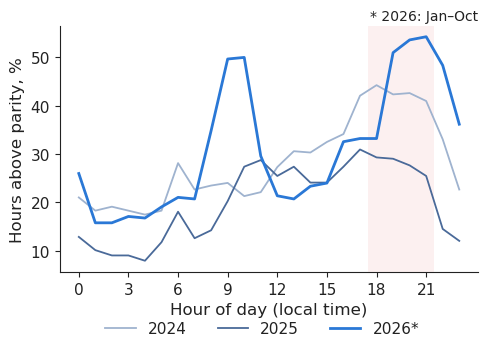

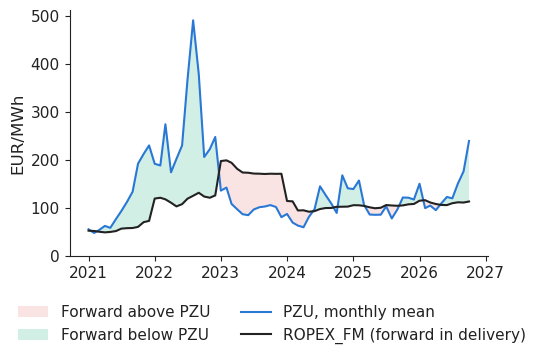

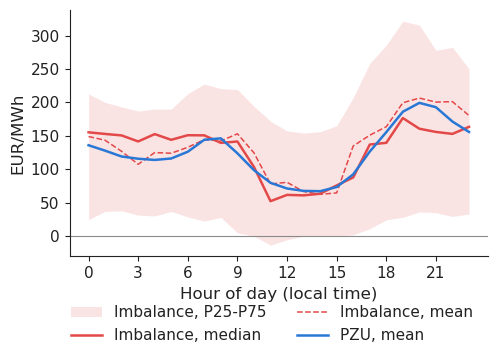

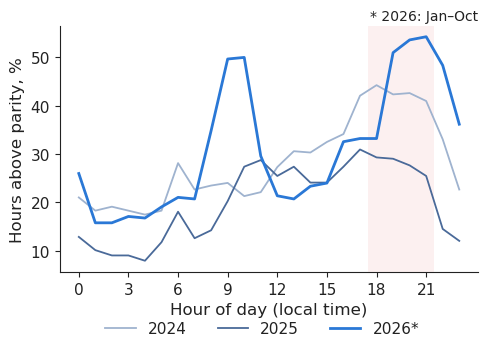

In [7]:
def fig_forward(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        z = F.loc["2021-01":]
        x = z.index.to_timestamp()
        ax.fill_between(x, z.pzu, z.fwd, where=z.fwd >= z.pzu, color=cu.EVENT, alpha=0.15, lw=0, interpolate=True,
                        label=cu.T(lang, "Forward above PZU", "Termen peste PZU"))
        ax.fill_between(x, z.pzu, z.fwd, where=z.fwd < z.pzu, color=cu.PAL["HU"], alpha=0.2, lw=0, interpolate=True,
                        label=cu.T(lang, "Forward below PZU", "Termen sub PZU"))
        ax.plot(x, z.pzu, color=cu.PAL["RO"], lw=1.5, label=cu.T(lang, "PZU, monthly mean", "PZU, media lunară"))
        ax.plot(x, z.fwd, color=cu.INK, lw=1.5, label=cu.T(lang, "ROPEX_FM (forward in delivery)", "ROPEX_FM (contracte în livrare)"))
        ax.set_ylabel("EUR/MWh"); ax.set_ylim(0, None)
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_forward, "f10_forward")

def fig_imbalance(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        ax.fill_between(bh.index, bh.q25, bh.q75, color=cu.PAL["c8"], alpha=0.15, lw=0, label=cu.T(lang, "Imbalance, P25-P75", "Dezechilibru, P25–P75"))
        ax.plot(bh.index, bh.med, color=cu.PAL["c8"], lw=1.8, label=cu.T(lang, "Imbalance, median", "Dezechilibru, mediana"))
        ax.plot(bh.index, bh.imb, color=cu.PAL["c8"], lw=1.1, ls="--", label=cu.T(lang, "Imbalance, mean", "Dezechilibru, media"))
        ax.plot(bh.index, bh.pzu, color=cu.PAL["RO"], lw=1.8, label=cu.T(lang, "PZU, mean", "PZU, media"))
        ax.axhline(0, color=cu.MUTED, lw=0.8)
        ax.set_xticks(range(0, 24, 3)); ax.set_xlabel(cu.T(lang, "Hour of day (local time)", "Ora din zi (ora locală)"))
        ax.set_ylabel("EUR/MWh")
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_imbalance, "f11_imbalance")

def fig_parity(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        cols = {2024: "#9fb3cf", 2025: "#4a6a99", 2026: cu.PAL["RO"]}
        for y, c in cols.items():
            z = IP.loc[str(y)]; s = z.groupby(z.index.hour).above.mean() * 100
            ax.plot(s.index, s.values, color=c, lw=2.0 if y == 2026 else 1.3, label=str(y) + ("*" if y == 2026 else ""))
        ax.axvspan(17.5, 21.5, color=cu.EVENT, alpha=0.08, lw=0)
        ax.set_xticks(range(0, 24, 3)); ax.set_xlabel(cu.T(lang, "Hour of day (local time)", "Ora din zi (ora locală)"))
        ax.set_ylabel(cu.T(lang, "Hours above parity, %", "Ore peste paritate, %"))
        ax.text(1, 1.01, cu.T(lang, "* 2026: Jan–Oct", "* 2026: ian.–oct."), transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
        cu.legend_bottom(fig, ncol=3, y=0.0)
    return fig
cu.save_both(fig_parity, "f12_import_parity")

**Read the charts.** Forward contracts in delivery cost far more than the PZU in 2023 and were close to it or below it afterwards.
Imbalance prices are much more dispersed than the PZU, most of all around midday: the cost of an imbalance is mainly a matter of volatility.
Romania is above import parity (and the import border congested) in a minority of hours, concentrated in the evening.

## 3. The fact: retail prices (Eurostat)

In [8]:
hhp = eurostat("nrg_pc_204", "EUR"); hpp = eurostat("nrg_pc_204", "PPS"); nhp = eurostat("nrg_pc_205", "EUR")
hhc = eurostat("nrg_pc_204_c", "EUR"); nhc = eurostat("nrg_pc_205_c", "EUR")
print(json.dumps(json.load(open(os.path.join(ES_DIR, "download_log.json"))), indent=1))
HB, NB = "KWH2500-4999", "MWH2000-19999"     # household band DC; non-household band ID
def semester(df, band, tax):
    s = df[(df.nrg_cons == band) & (df.tax == tax)].pivot_table(index="time", columns="geo", values="value")
    return s[ES_GEO]
h_inc = semester(hhp, HB, "I_TAX"); h_pps = semester(hpp, HB, "I_TAX"); n_xv = semester(nhp, NB, "X_VAT")
LASTS = h_inc.dropna(subset=["RO", "EU27_2020"]).index[-1]
print("latest semester:", LASTS)
print("households, all taxes, EUR/kWh\n", h_inc.tail(4).round(4))
print("households, all taxes, PPS/kWh\n", h_pps.tail(4).round(4))
print("non-households (band ID), excl. VAT, EUR/kWh\n", n_xv.tail(4).round(4))

def comps(df, band, year):
    s = df[(df.nrg_cons == band) & (df.time == year)].pivot_table(index="geo", columns="nrg_prc", values="value").loc[ES_GEO]
    return pd.DataFrame({"energy": s.NRG_SUP, "network": s.NETC, "taxes": s.TAX_FEE_LEV_CHRG - s.VAT, "vat": s.VAT})
LASTY = sorted(hhc.time.unique())[-1]
ch, cn = comps(hhc, HB, LASTY), comps(nhc, NB, LASTY)
print("components", LASTY, "households\n", ch.round(4), "\nnon-households\n", cn.round(4))

{
 "nrg_pc_204_EUR.json": {
  "url": "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/nrg_pc_204?format=JSON&lang=EN&geo=RO&geo=HU&geo=BG&geo=PL&geo=DE&geo=EU27_2020&currency=EUR",
  "downloaded": "2026-11-05",
  "eurostat_updated": "2026-10-19T23:00:00+0200"
 },
 "nrg_pc_204_PPS.json": {
  "url": "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/nrg_pc_204?format=JSON&lang=EN&geo=RO&geo=HU&geo=BG&geo=PL&geo=DE&geo=EU27_2020&currency=PPS",
  "downloaded": "2026-11-05",
  "eurostat_updated": "2026-10-19T23:00:00+0200"
 },
 "nrg_pc_205_EUR.json": {
  "url": "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/nrg_pc_205?format=JSON&lang=EN&geo=RO&geo=HU&geo=BG&geo=PL&geo=DE&geo=EU27_2020&currency=EUR",
  "downloaded": "2026-11-05",
  "eurostat_updated": "2026-10-19T11:00:00+0200"
 },
 "nrg_pc_204_c_EUR.json": {
  "url": "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/nrg_pc_204_c?format=JSON&lang=EN&geo=RO&geo=HU

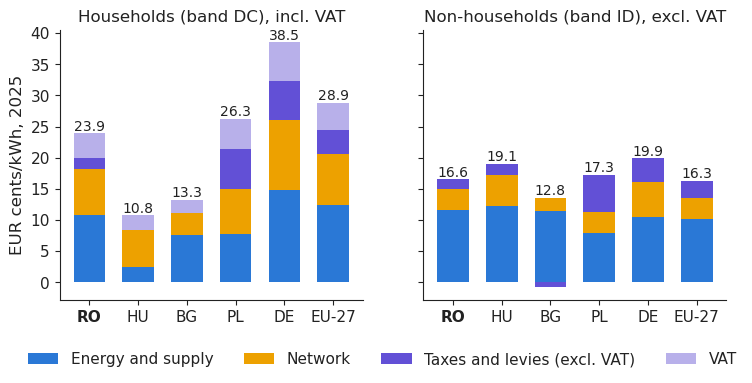

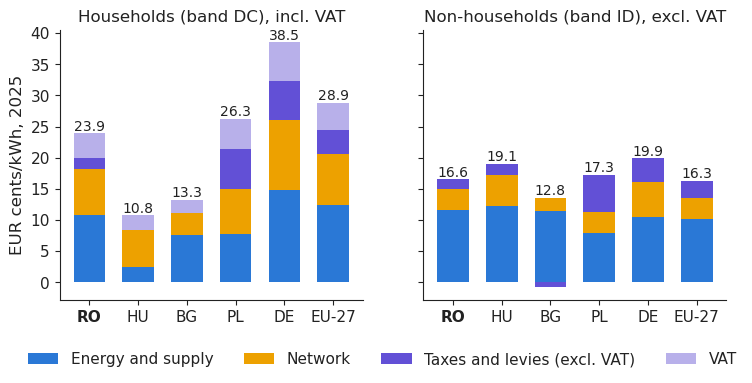

In [9]:
CC = {"energy": cu.PAL["RO"], "network": cu.PAL["BG"], "taxes": cu.PAL["c7"], "vat": "#b8b0ea"}
CL = {"energy": ("Energy and supply", "Energie și furnizare"), "network": ("Network", "Rețea"),
      "taxes": ("Taxes and levies (excl. VAT)", "Taxe și contribuții (fără TVA)"), "vat": ("VAT", "TVA")}
def fig_retail(lang):
    with big(lang):
        fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5), sharey=True)
        for ax, c, parts, ttl in [(axes[0], ch, ["energy", "network", "taxes", "vat"], ("Households (band DC), incl. VAT", "Consumatori casnici (banda DC), cu TVA")),
                                  (axes[1], cn, ["energy", "network", "taxes"], ("Non-households (band ID), excl. VAT", "Consumatori noncasnici (banda ID), fără TVA"))]:
            x = np.arange(len(ES_GEO)); bottom = np.zeros(len(ES_GEO))
            pos = np.zeros(len(ES_GEO))
            for p_ in parts:
                v = (c[p_].values * 100)
                ax.bar(x, v, bottom=np.where(v >= 0, pos, 0), color=CC[p_], width=0.65, label=cu.T(lang, *CL[p_]))
                pos += np.clip(v, 0, None); bottom += v
            top = sum(np.clip(c[p_].values * 100, 0, None) for p_ in parts)
            for xi, b, tp in zip(x, bottom, top):
                ax.text(xi, tp + 0.4, cu.fmt(b, 1, lang), ha="center", fontsize=10)
            ax.set_xticks(x); ax.set_xticklabels([cu.T(lang, "EU-27", "UE-27") if g == "EU27_2020" else g for g in ES_GEO], fontsize=11)
            ax.get_xticklabels()[0].set_fontweight("bold")
            ax.set_title(cu.T(lang, *ttl))
            cu.comma_axis(ax, lang)
        axes[0].set_ylabel(cu.T(lang, f"EUR cents/kWh, {LASTY}", f"eurocenți/kWh, {LASTY}"))
        cu.legend_bottom(fig, ncol=4, y=0.0)
    return fig
cu.save_both(fig_retail, "f3_retail_components")

**Read the chart.** In euro, a Romanian household pays about the EU average and far more than in Hungary and Bulgaria, which keep regulated household tariffs.
Measured in purchasing power standards (PPS) the Romanian household price is the highest in the group. For firms the gap with the EU is in the *energy and supply* component;
network charges are close to the EU average and taxes are lower.

## 4. Driver 1: the evening deficit and imports

2026 solar at 13:00 1714 MW; net imports 13:00 -555 MW, 19:00-21:00 1139 MW
       base    eve   mid  capture  capture_rate
2023  103.7  146.3  86.8     83.2          80.2
2024  103.5  174.3  70.6     68.0          65.7
2025  108.2  166.8  68.6     64.4          59.6
2026  137.4  199.2  77.8     86.3          62.8


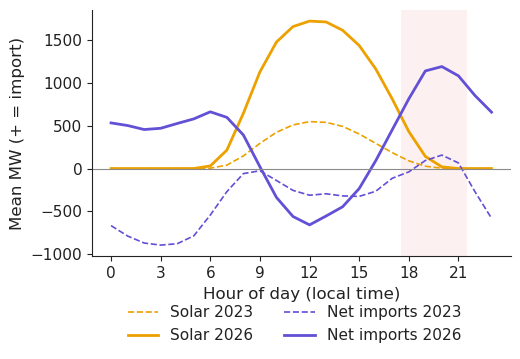

In [10]:
def hourly_mean(s, y):
    z = s.loc[str(y)]
    return z.groupby(z.index.hour).mean()
sol23, sol26 = hourly_mean(gh.solar, 2023), hourly_mean(gh.solar, 2026)
imp23, imp26 = hourly_mean(xh["sum"], 2023), hourly_mean(xh["sum"], 2026)
def fig_evening(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        ax.plot(sol23.index, sol23, color=cu.PAL["BG"], ls="--", lw=1.2, label=cu.T(lang, "Solar 2023", "Solar 2023"))
        ax.plot(sol26.index, sol26, color=cu.PAL["BG"], lw=2.0, label=cu.T(lang, "Solar 2026", "Solar 2026"))
        ax.plot(imp23.index, imp23, color=cu.PAL["c7"], ls="--", lw=1.2, label=cu.T(lang, "Net imports 2023", "Importuri nete 2023"))
        ax.plot(imp26.index, imp26, color=cu.PAL["c7"], lw=2.0, label=cu.T(lang, "Net imports 2026", "Importuri nete 2026"))
        ax.axhline(0, color=cu.MUTED, lw=0.8); ax.axvspan(17.5, 21.5, color=cu.EVENT, alpha=0.08, lw=0)
        ax.set_xticks(range(0, 24, 3)); ax.set_xlabel(cu.T(lang, "Hour of day (local time)", "Ora din zi (ora locală)"))
        ax.set_ylabel(cu.T(lang, "Mean MW (+ = import)", "MW, medie (+ = import)"))
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_evening, "f4_evening")
print("2026 solar at 13:00 %.0f MW; net imports 13:00 %.0f MW, 19:00-21:00 %.0f MW" % (sol26[13], imp26[13], imp26[[19, 20, 21]].mean()))
# price shape inside the day and the value captured by a solar profile (pay-as-produced PPA)
def shape(y):
    z = ph.RO.loc[str(y)]; zs = gh.solar.reindex(z.index)
    ok = zs.notna()
    return {"base": z.mean(), "eve": z[z.index.hour.isin(EVE)].mean(), "mid": z[z.index.hour.isin(MID)].mean(),
            "capture": (z[ok] * zs[ok]).sum() / zs[ok].sum()}
shp = pd.DataFrame({y: shape(y) for y in [2023, 2024, 2025, 2026]}).T
shp["capture_rate"] = shp.capture / shp.base * 100
print(shp.round(1))

**Read the chart.** Solar output at noon has grown strongly; Romania now *exports* at midday and *imports* in the evening.
In the evening the system relies more on imports (and, possibly, on more expensive domestic units), and this is when the RO-DE premium peaks.

## 5. Drivers 2-3: hydro and nuclear

hydro: mean 2015-2024 1857 MW (Jan-Oct 1908); 2025 1387; 2026 Jan-Oct 1431


nuclear: mean 2015-2024 1289 MW; 2026 Jan-Oct 774 MW; days 2026 <50 MW: 70, 50-900 MW: 59, missing: 29


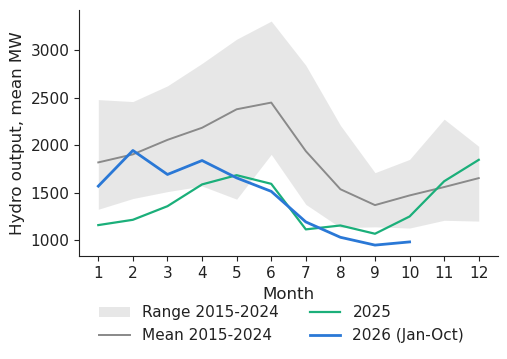

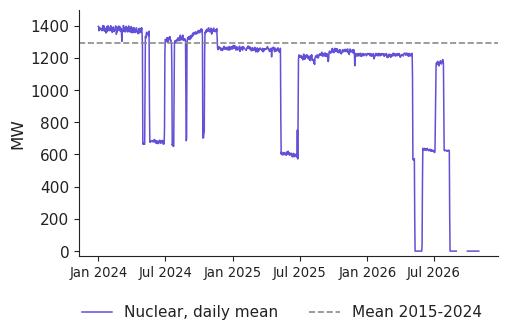

In [11]:
hm = gd.hydro.resample("MS").mean()
ref = hm.loc["2015":"2024"]
clim = ref.groupby(ref.index.month).agg(["mean", "min", "max"])
h25, h26 = hm.loc["2025"], hm.loc["2026"]
def fig_hydro(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        ax.fill_between(clim.index, clim["min"], clim["max"], color=cu.MUTED, alpha=0.2, lw=0, label=cu.T(lang, "Range 2015-2024", "Interval 2015–2024"))
        ax.plot(clim.index, clim["mean"], color=cu.MUTED, lw=1.4, label=cu.T(lang, "Mean 2015-2024", "Media 2015–2024"))
        ax.plot(h25.index.month, h25.values, color=cu.PAL["HU"], lw=1.6, label="2025")
        ax.plot(h26.index.month, h26.values, color=cu.PAL["RO"], lw=2.0, label=cu.T(lang, "2026 (Jan-Oct)", "2026 (ian.–oct.)"))
        ax.set_xticks(range(1, 13)); ax.set_xlabel(cu.T(lang, "Month", "Luna"))
        ax.set_ylabel(cu.T(lang, "Hydro output, mean MW", "Producția hidro, MW, medie"))
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_hydro, "f5_hydro")
href = gd.hydro.loc["2015":"2024"].mean()
h25m, h26m = gd.hydro.loc["2025"].mean(), gd.hydro.loc["2026"].mean()
href_janoct = gd.hydro.loc["2015":"2024"][gd.hydro.loc["2015":"2024"].index.month <= 10].mean()
print("hydro: mean 2015-2024 %.0f MW (Jan-Oct %.0f); 2025 %.0f; 2026 Jan-Oct %.0f" % (href, href_janoct, h25m, h26m))

nuc = gd.nuclear.loc["2024-01-01":END]
nref = gd.nuclear.loc["2015":"2024"].mean()
n26 = gd.nuclear.loc["2026"]
n_zero = int((n26 < NUC_OFF).sum()); n_low = int(((n26 >= NUC_OFF) & (n26 < NUC_ONE)).sum()); n_na = int(n26.isna().sum())
def fig_nuclear(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        ax.plot(nuc.index, nuc.values, color=cu.PAL["c7"], lw=1.1, label=cu.T(lang, "Nuclear, daily mean", "Nuclear, media zilnică"))
        ax.axhline(nref, color=cu.MUTED, ls="--", lw=1.2, label=cu.T(lang, "Mean 2015-2024", "Media 2015–2024"))
        ax.set_ylabel("MW"); ax.set_ylim(-30, 1500)
        import matplotlib.dates as mdates
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y" if lang == "ro" else "%b %Y"))
        plt.setp(ax.get_xticklabels(), fontsize=9.5)
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_nuclear, "f6_nuclear")
print("nuclear: mean 2015-2024 %.0f MW; 2026 Jan-Oct %.0f MW; days 2026 <50 MW: %d, 50-900 MW: %d, missing: %d" % (nref, n26.mean(), n_zero, n_low, n_na))

**Read the charts.** Hydro output in 2025 and 2026 is below the 2015-2024 mean in most months.
Nuclear output is close to its usual level until early May 2026; afterwards the series shows long periods at about half output or at zero.
We only describe what the generation data show; the reasons for each outage (planned maintenance, unplanned events) are outside our data.

## 6. Driver 4: gas as the marginal fuel (SRMC)

The short-run marginal cost of a gas plant with electrical efficiency $\eta$ is

$$\text{SRMC}_t = \frac{P^{\text{TTF}}_t}{\eta} + P^{\text{EUA}}_t \cdot \frac{e_{th}}{\eta}\qquad [\text{EUR/MWh}_{el}],$$

where $P^{\text{TTF}}$ is the TTF (Title Transfer Facility, Dutch gas hub) price in EUR/MWh of gas (thermal), $P^{\text{EUA}}$ the price of an EU emission allowance (EUA, 1 tCO2)
and $e_{th}=0.202$ tCO2/MWh$_{th}$ the emission factor of natural gas. With $\eta=0.5$ one MWh of electricity burns 2 MWh of gas and emits $0.202/0.5=0.404$ tCO2.
Variable operation and maintenance costs and gas transport tariffs are ignored (a few EUR/MWh).

             ttf   eua   srmc     lo     hi     RO   gap
2025-09-01  32.3  75.5   95.2   82.0  119.0   97.1   1.9
2025-10-01  31.9  77.9   95.4   82.2  119.2  121.9  26.5
2025-11-01  30.8  80.7   94.1   81.1  117.6  121.5  27.4
2025-12-01  27.6  83.7   89.1   76.8  111.3  117.6  28.6
2026-01-01  34.2  85.6  103.0   88.8  128.7  150.5  47.6
2026-02-01  32.4  73.0   94.4   81.4  118.0   99.7   5.4
2026-03-01  52.9  68.1  133.2  114.9  166.6  105.1 -28.1
2026-04-01  44.9  72.1  118.9  102.5  148.7   95.6 -23.4
2026-05-01  47.3  74.4  124.6  107.4  155.7  109.6 -15.0
2026-06-01  44.9  77.2  121.1  104.4  151.3  123.0   1.9
2026-07-01  54.0  79.5  140.0  120.7  175.1  120.1 -19.9
2026-08-01  62.1  80.6  156.8  135.2  196.0  151.2  -5.7
2026-09-01  75.3  84.0  184.6  159.1  230.7  176.1  -8.4
2026-10-01  86.8  85.1  208.0  179.3  260.0  239.3  31.3
corr(RO, SRMC) monthly 2023-2026: 0.77; mean RO-SRMC 2023-2026: 0.0


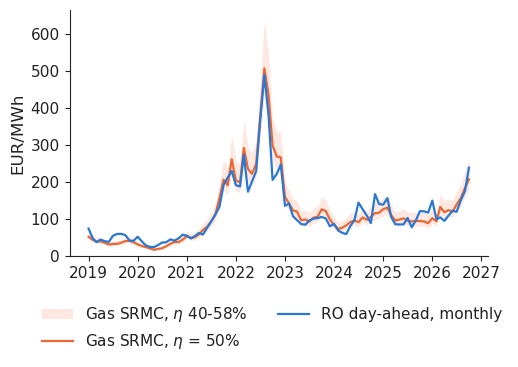

In [12]:
def srmc(eta):
    return ttf / eta + eua_m.reindex(ttf.index) * EF_TH / eta
S = pd.DataFrame({"ttf": ttf, "eua": eua_m.reindex(ttf.index), "srmc": srmc(ETA), "lo": srmc(ETA_HI), "hi": srmc(ETA_LO),
                  "RO": pd_.RO.resample("MS").mean()}).loc["2019-01-01":END]
S["gap"] = S.RO - S.srmc
def fig_srmc(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        ax.fill_between(S.index, S.lo, S.hi, color=cu.PAL["DE_LU"], alpha=0.15, lw=0,
                        label=cu.T(lang, "Gas SRMC, $\\eta$ 40-58%", "SRMC gaze, $\\eta$ 40–58%"))
        ax.plot(S.index, S.srmc, color=cu.PAL["DE_LU"], lw=1.6, label=cu.T(lang, "Gas SRMC, $\\eta$ = 50%", "SRMC gaze, $\\eta$ = 50%"))
        ax.plot(S.index, S.RO, color=cu.PAL["RO"], lw=1.6, label=cu.T(lang, "RO day-ahead, monthly", "PZU România, lunar"))
        ax.set_ylabel("EUR/MWh"); ax.set_ylim(0, None)
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_srmc, "f7_srmc")
s23 = S.loc["2023":]
corr_srmc = s23[["RO", "srmc"]].corr().iloc[0, 1]
print(S.loc["2024":].round(1).tail(14))
print("corr(RO, SRMC) monthly 2023-2026: %.2f; mean RO-SRMC 2023-2026: %.1f" % (corr_srmc, s23.gap.mean()))

**Read the chart.** Since 2023 the monthly Romanian price tracks the gas SRMC closely, consistent with gas units setting the price in many hours.
In autumn 2026, with TTF above 70 EUR/MWh, the SRMC rises above 180 EUR/MWh and the Romanian price follows. The level depends on the assumed efficiency (band).

## 7. Driver 5: coupling, congestion and the coal decline

share of MTUs with |RO - X| > 1 EUR/MWh, %
                  HU    BG
timestamp_utc            
2019           16.4  92.0
2020           12.9  86.9
2021           13.4  78.2
2022           33.4  13.6
2023           31.3   2.8
2024           44.8   5.2
2025           36.5   3.4
2026           39.1  20.4 
evening
                  HU    BG
timestamp_utc            
2019           15.1  91.5
2020           13.2  84.8
2021           10.2  80.3
2022           32.6  12.5
2023           40.0   2.4
2024           62.6   5.5
2025           56.4   0.7
2026           52.8  32.7


coal MW by year
 {2019: 1582.0, 2020: 1095.0, 2021: 1250.0, 2022: 1204.0, 2023: 933.0, 2024: 793.0, 2025: 749.0, 2026: 628.0} 
gas MW by year
 {2019: 1064.0, 2020: 1158.0, 2021: 1222.0, 2022: 1212.0, 2023: 1095.0, 2024: 1169.0, 2025: 1092.0, 2026: 1065.0}
RO battery discharge, quarterly mean MW
 {Timestamp('2025-03-31 00:00:00'): 14.0, Timestamp('2025-06-30 00:00:00'): 20.0, Timestamp('2025-09-30 00:00:00'): 25.0, Timestamp('2025-12-31 00:00:00'): 30.0, Timestamp('2026-03-31 00:00:00'): 48.0, Timestamp('2026-06-30 00:00:00'): 51.0, Timestamp('2026-09-30 00:00:00'): 69.0, Timestamp('2026-12-31 00:00:00'): 88.0}
BG battery series starts 2026-09-09 | Oct 2026 mean discharge 576 MW, charging -715 MW
RO - BG, evening, Sep-Oct 2026: 26.3 EUR/MWh


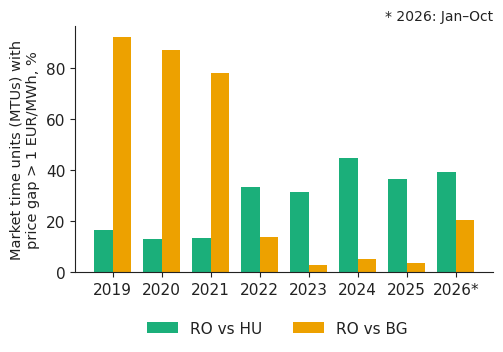

In [13]:
THR = 1.0   # EUR/MWh; "separation" = absolute RO-X price difference above THR
sep = pd.DataFrame({z: ((pn.RO - pn[z]).abs() > THR).astype(float).where(pn.RO.notna() & pn[z].notna()) for z in ["HU", "BG"]})  # NaN where a price is missing
sep_y = sep.groupby(sep.index.year).mean() * 100
sepe = sep[sep.index.tz_convert("Europe/Bucharest").hour.isin(EVE)]
sep_eve = sepe.groupby(sepe.index.year).mean() * 100
print("share of MTUs with |RO - X| > 1 EUR/MWh, %\n", sep_y.round(1), "\nevening\n", sep_eve.round(1))
def fig_sep(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(5.4, 3.2))
        x = np.arange(len(sep_y)); wdt = 0.38
        ax.bar(x - wdt / 2, sep_y.HU, wdt, color=cu.PAL["HU"], label=cu.T(lang, "RO vs HU", "RO față de HU"))
        ax.bar(x + wdt / 2, sep_y.BG, wdt, color=cu.PAL["BG"], label=cu.T(lang, "RO vs BG", "RO față de BG"))
        ax.set_xticks(x); ax.set_xticklabels([str(y) + ("*" if y == 2026 else "") for y in sep_y.index])
        ax.set_ylabel(cu.T(lang, "Market time units (MTUs) with\nprice gap > 1 EUR/MWh, %", "Intervale de piață (MTU) cu\ndiferență > 1 EUR/MWh, %"), fontsize=10.5)
        ax.text(1, 1.01, cu.T(lang, "* 2026: Jan–Oct", "* 2026: ian.–oct."), transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
        cu.legend_bottom(fig, ncol=2, y=0.0)
    return fig
cu.save_both(fig_sep, "f8_separation")
coal = yr(gd.coal.loc["2019":END]).mean(); gas = yr(gd.gas.loc["2019":END]).mean()
print("coal MW by year\n", coal.round(0).to_dict(), "\ngas MW by year\n", gas.round(0).to_dict())
rob = gd.battery.loc["2025":END].resample("QE").mean()
bgb = gbd[["battery", "battery_consumption"]].dropna(how="all")
print("RO battery discharge, quarterly mean MW\n", rob.round(0).to_dict())
print("BG battery series starts", bgb.index.min().date(), "| Oct 2026 mean discharge %.0f MW, charging %.0f MW" %
      (bgb.loc["2026-10", "battery"].mean(), bgb.loc["2026-10", "battery_consumption"].mean()))
bg_eve = hh.loc["2026-09-01":END]; bg_eve = bg_eve[bg_eve.index.hour.isin(EVE)].dBG.mean()
print("RO - BG, evening, Sep-Oct 2026: %.1f EUR/MWh" % bg_eve)

**Read the chart.** Romania is market-coupled with its neighbours, and in most hours its price equals at least one neighbour's price. Separation from Hungary
(different prices, a sign of a congested interconnector or a binding flow-based constraint) occurs in a large minority of the 15-minute and hourly market time units (MTUs);
separation from Bulgaria was rare in 2023-2025 and is frequent again in 2026. Coal output has fallen by more than half since 2019.

## 8. A simple model and an accounting decomposition

Daily regression, January 2023 - October 2026:

$$P_d = \alpha + \beta_1 RL_d + \beta_2 H_d + \beta_3 N_d + \beta_4 M_d + \beta_5\,\text{SRMC}_{d} + \sum_{k=2}^{12}\gamma_k \mathbf{1}[\text{month}(d)=k] + u_d ,$$

with $P_d$ the daily RO base price (EUR/MWh), $RL_d$ residual load (load minus wind minus solar), $H_d$ hydro, $N_d$ nuclear, $M_d$ net imports (all in GW, daily means)
and $\text{SRMC}_{d}$ the gas SRMC *known on day d* (TTF of the previous month, last EUA price before d). In-sample, explanatory regression on a chronological sample; the physical regressors are same-day realised values, so it is not a forecasting model. Standard errors: Newey-West HAC with 7 lags (on the retained days) and, as a check, clustered by month.

**Accounting decomposition.** For two periods $A$ (Jan-Oct 2024) and $B$ (Jan-Oct 2026),
$\bar P_B-\bar P_A=\sum_k \hat\beta_k(\bar x_{k,B}-\bar x_{k,A}) + (\bar{\hat u}_B-\bar{\hat u}_A)$.
Each term is a coefficient times a change in means. The drivers are correlated, so the split between them is not unique and is **not causal**.

In [14]:
D = pd.DataFrame({"price": pd_.RO,
                  "resid": (gd.load - gd.wind_onshore - gd.solar) / 1000, "hydro": gd.hydro / 1000,
                  "nuclear": gd.nuclear / 1000, "netimp": xd["sum"] / 1000}).loc[REG_START:END]
# SRMC known on day d: TTF of the PREVIOUS month (the monthly average of month m is only known after m ends)
# and the last EUA price published BEFORE day d.
# the World Bank publishes month m-1 in the first days of month m: use m-1 from day TTF_PUB_DAY, m-2 before it
TTF_PUB_DAY = 6
eua_prev = eua_d.reindex(pd.date_range("2015-01-01", END)).ffill().shift(1)
_lag = np.where(D.index.day >= TTF_PUB_DAY, 1, 2)
_m = D.index.to_period("M")
_ttf_known = np.array([ttf.get((m - k).to_timestamp(), np.nan) for m, k in zip(_m, _lag)])
D["srmc"] = (_ttf_known / ETA
             + eua_prev.reindex(D.index).values * EF_TH / ETA)
n_cal = len(D); D = D.dropna(); n_drop = n_cal - len(D)
MD = pd.get_dummies(D.index.month, prefix="m", drop_first=True).astype(float); MD.index = D.index
XV = ["resid", "hydro", "nuclear", "netimp", "srmc"]
X = sm.add_constant(pd.concat([D[XV], MD], axis=1))
# in-sample, chronological sample, no out-of-sample claim; HAC (Newey-West) on the retained days, plus month-clustered s.e. as a check
ols = sm.OLS(D.price, X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
ols_cl = sm.OLS(D.price, X).fit(cov_type="cluster", cov_kwds={"groups": D.index.to_period("M").astype(str).factorize()[0]})
print(ols.summary().tables[1])
print("calendar days %d, dropped (missing data) %d; month-clustered s.e.:" % (n_cal, n_drop), ols_cl.bse[XV].round(2).to_dict())
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)[XV]
print("R2 %.3f, n = %d; VIF:" % (ols.rsquared, ols.nobs), vif.round(2).to_dict())

def decompose(a, b):
    A = (D.index >= f"{a}-01-01") & (D.index <= f"{a}-10-31"); B = (D.index >= f"{b}-01-01") & (D.index <= f"{b}-10-31")
    xa, xb = X[A].mean(), X[B].mean()
    contrib = ols.params * (xb - xa)
    out = {k: contrib[k] for k in XV}
    out["calendar"] = contrib[[c for c in X.columns if c.startswith("m_")]].sum()
    out["unexplained"] = (ols.resid[B].mean() - ols.resid[A].mean())
    return pd.Series(out), D.price[A].mean(), D.price[B].mean(), xa, xb, int(A.sum()), int(B.sum())
dec, pA, pB, xa, xb, nA, nB = decompose(2024, 2026)
print("mean price Jan-Oct 2024 %.1f, Jan-Oct 2026 %.1f, change %.1f" % (pA, pB, pB - pA))
print(dec.round(2), "\nsum check:", round(dec.sum() - (pB - pA), 6))
dec23, pA23, pB23, *_ = decompose(2023, 2026)
print("reference 2023: change %.1f\n" % (pB23 - pA23), dec23.round(2))

DL = {"resid": ("Residual load, GW", "Consum rezidual, GW"), "hydro": ("Hydro, GW", "Hidro, GW"), "nuclear": ("Nuclear, GW", "Nuclear, GW"),
      "netimp": ("Net imports, GW", "Importuri nete, GW"), "srmc": ("Gas SRMC, EUR/MWh", "SRMC gaze, EUR/MWh")}
treg = pd.DataFrame({"b": ols.params[XV], "se": ols.bse[XV], "secl": ols_cl.bse[XV], "xa": xa[XV], "xb": xb[XV], "dx": (xb - xa)[XV], "c": dec[XV]})
treg.index = [DL[k] for k in XV]
cu.write_table(treg, "regression",
    header=[("Driver", "Factor"), ("$\\hat\\beta$", "$\\hat\\beta$"), ("HAC s.e.", "Eroare std. HAC"), ("Cluster s.e.", "Eroare std. cluster"), ("Mean 2024*", "Media 2024*"),
            ("Mean 2026*", "Media 2026*"), ("$\\Delta$ mean", "$\\Delta$ medie"), ("Contribution, EUR/MWh", "Contribuția, EUR/MWh")],
    digits={"b": 2, "se": 2, "secl": 2, "xa": 2, "xb": 2, "dx": 2, "c": 1})

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -39.9328     17.276     -2.311      0.021     -73.794      -6.072
resid         42.2328      4.233      9.977      0.000      33.936      50.530
hydro        -27.7915      5.938     -4.680      0.000     -39.430     -16.153
nuclear      -69.4026      7.870     -8.819      0.000     -84.827     -53.978
netimp       -14.8766      4.809     -3.093      0.002     -24.302      -5.451
srmc           0.4509      0.059      7.581      0.000       0.334       0.567
m_2            1.9082      6.696      0.285      0.776     -11.216      15.032
m_3            8.4993      6.952      1.223      0.221      -5.126      22.124
m_4           26.6593      8.992      2.965      0.003       9.035      44.284
m_5            9.0689     10.304      0.880      0.379     -11.126      29.264
m_6            6.7923     10.450      0.650      0.5

R2 0.569, n = 1371; VIF: {'resid': 11.1, 'hydro': 6.17, 'nuclear': 3.13, 'netimp': 9.62, 'srmc': 1.33}
mean price Jan-Oct 2024 93.4, Jan-Oct 2026 133.3, change 39.9
resid         -23.06
hydro           6.27
nuclear        30.89
netimp         -0.94
srmc           14.20
calendar       -1.36
unexplained    13.92
dtype: float64 
sum check: -0.0
reference 2023: change 27.0
 resid         -18.71
hydro          18.45
nuclear        35.03
netimp         -9.95
srmc           -5.41
calendar       -1.41
unexplained     9.03
dtype: float64


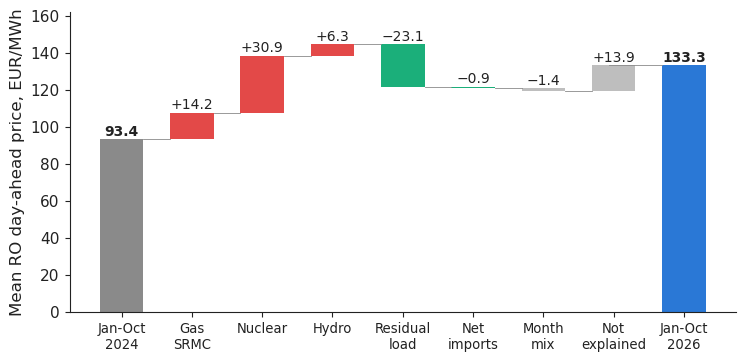

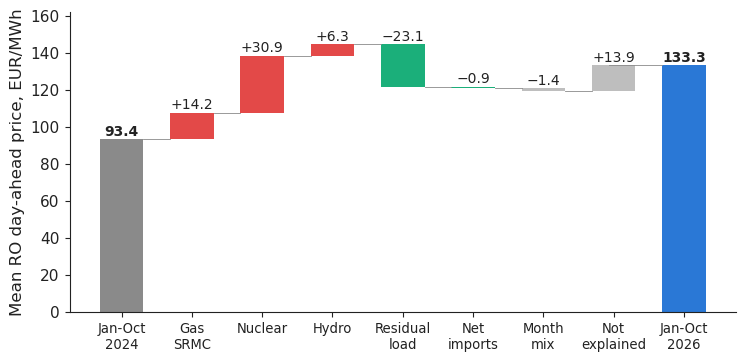

In [15]:
WL = {"resid": ("Residual\nload", "Consum\nrezidual"), "hydro": ("Hydro", "Hidro"), "nuclear": ("Nuclear", "Nuclear"),
      "netimp": ("Net\nimports", "Import\nnet"), "srmc": ("Gas\nSRMC", "SRMC\ngaze"), "calendar": ("Month\nmix", "Structura\nlunilor"),
      "unexplained": ("Not\nexplained", "Rest\nneexplicat")}
def fig_waterfall(lang):
    with big(lang):
        fig, ax = plt.subplots(figsize=(8.6, 3.9))
        keys = ["srmc", "nuclear", "hydro", "resid", "netimp", "calendar", "unexplained"]
        labels = [cu.T(lang, "Jan-Oct\n2024", "ian.–oct.\n2024")] + [cu.T(lang, *WL[k]) for k in keys] + [cu.T(lang, "Jan-Oct\n2026", "ian.–oct.\n2026")]
        ax.bar(0, pA, color=cu.MUTED, width=0.62)
        level = pA; peak = max(pA, pB)
        for i, k in enumerate(keys, start=1):
            v = dec[k]
            col = cu.MUTED if k in ("calendar", "unexplained") else (cu.EVENT if v > 0 else cu.PAL["HU"])
            ax.bar(i, v, bottom=level, color=col, width=0.62, alpha=0.55 if k in ("calendar", "unexplained") else 1)
            ax.text(i, max(level, level + v) + 2, cu.fmt(v, 1, lang, sign=True).replace("-", "−"), ha="center", fontsize=10)
            ax.plot([i - 0.31 - 0.38, i - 0.31], [level, level], color=INKL, lw=0.6)
            level += v; peak = max(peak, level)
        ax.bar(len(keys) + 1, pB, color=cu.PAL["RO"], width=0.62)
        ax.plot([len(keys) + 0.31 - 0.38, len(keys) + 0.69], [level, level], color=INKL, lw=0.6)
        for xi, v in [(0, pA), (len(keys) + 1, pB)]:
            ax.text(xi, v + 2, cu.fmt(v, 1, lang), ha="center", fontsize=10, fontweight="bold")
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=9.5)
        ax.set_ylabel(cu.T(lang, "Mean RO day-ahead price, EUR/MWh", "Prețul mediu PZU, EUR/MWh"))
        ax.set_ylim(0, peak * 1.12)
        cu.comma_axis(ax, lang)
    return fig
INKL = cu.MUTED
cu.save_both(fig_waterfall, "f9_waterfall", headline=True)

**Read the result.** In this in-sample fit the largest positive terms are lower nuclear output and the higher gas SRMC; lower hydro output adds a smaller term,
and lower residual load (more solar and wind, weaker demand) enters with a negative term. The unexplained part is not small. The terms are *associations within this model*;
another specification, another reference year or a different treatment of imports would move them (try 2023 as reference below).

## 9. Numbers for the brief

In [16]:
lastsem = LASTS
def f(x, nd=1, lang="en"):
    return cu.fmt(x, nd, lang)
nums = {
    "roTwentySix": ann.loc[2026, "RO"], "huTwentySix": ann.loc[2026, "HU"], "bgTwentySix": ann.loc[2026, "BG"], "deTwentySix": ann.loc[2026, "DE_LU"],
    "premHUTwentySix": ann.loc[2026, "RO_HU"], "premBGTwentySix": ann.loc[2026, "RO_BG"], "premDETwentySix": ann.loc[2026, "RO_DE"],
    "premDEavg": ann.loc[2019:2025, "RO_DE"].mean(), "premHUavg": ann.loc[2019:2025, "RO_HU"].mean(),
    "premDETwentyFour": ann.loc[2024, "RO_DE"], "premDETwentyFive": ann.loc[2025, "RO_DE"],
    "eveDETwentySix": ann.loc[2026, "eve_DE"], "midDETwentySix": ann.loc[2026, "mid_DE"],
    "eveDETwentyFour": ann.loc[2024, "eve_DE"], "midDETwentyFour": ann.loc[2024, "mid_DE"],
    "eveHUTwentySix": ann.loc[2026, "eve_HU"], "eveHUTwentyFour": ann.loc[2024, "eve_HU"],
    "roOct": m.loc["2026-10-01", "RO"], "deOct": m.loc["2026-10-01", "DE_LU"],
    # retail
    "lastSem": lastsem, "lastYear": LASTY,
    "hhRO": h_inc.loc[lastsem, "RO"] * 100, "hhEU": h_inc.loc[lastsem, "EU27_2020"] * 100, "hhHU": h_inc.loc[lastsem, "HU"] * 100,
    "hhBG": h_inc.loc[lastsem, "BG"] * 100, "hhROprev": h_inc.loc["2025-S1", "RO"] * 100,
    "ppsRO": h_pps.loc[lastsem, "RO"] * 100, "ppsEU": h_pps.loc[lastsem, "EU27_2020"] * 100,
    "ppsRatio": (h_pps.loc[lastsem, "RO"] / h_pps.loc[lastsem, "EU27_2020"] - 1) * 100,
    "nhRO": n_xv.loc[lastsem, "RO"] * 100, "nhEU": n_xv.loc[lastsem, "EU27_2020"] * 100, "nhHU": n_xv.loc[lastsem, "HU"] * 100, "nhBG": n_xv.loc[lastsem, "BG"] * 100,
    "chEnRO": ch.loc["RO", "energy"] * 100, "chEnEU": ch.loc["EU27_2020", "energy"] * 100,
    "chNetRO": ch.loc["RO", "network"] * 100, "chNetEU": ch.loc["EU27_2020", "network"] * 100,
    "chTaxRO": (ch.loc["RO", "taxes"] + ch.loc["RO", "vat"]) * 100, "chTaxEU": (ch.loc["EU27_2020", "taxes"] + ch.loc["EU27_2020", "vat"]) * 100,
    "chEnHU": ch.loc["HU", "energy"] * 100, "chEnBG": ch.loc["BG", "energy"] * 100,
    "cnEnRO": cn.loc["RO", "energy"] * 100, "cnEnEU": cn.loc["EU27_2020", "energy"] * 100,
    "cnNetRO": cn.loc["RO", "network"] * 100, "cnNetEU": cn.loc["EU27_2020", "network"] * 100,
    "cnTaxRO": cn.loc["RO", "taxes"] * 100, "cnTaxEU": cn.loc["EU27_2020", "taxes"] * 100,
    "cnTotRO": cn.loc["RO", ["energy", "network", "taxes"]].sum() * 100, "cnTotEU": cn.loc["EU27_2020", ["energy", "network", "taxes"]].sum() * 100,
    # drivers
    "solNoon": sol26[13], "solNoonTT": sol23[13], "impNoon": imp26[13], "impEve": imp26[[19, 20, 21]].mean(), "impEveTT": imp23[[19, 20, 21]].mean(),
    "hydroRef": href_janoct, "hydroTwentyFive": h25m, "hydroTwentySix": h26m,
    "hydroGap": (h26m / href_janoct - 1) * 100, "hydroGapFive": (h25m / href - 1) * 100,
    "nucRef": nref, "nucTwentySix": n26.mean(), "nucZero": n_zero, "nucLow": n_low, "nucNA": n_na,
    "srmcTwentySix": S.loc["2026", "srmc"].mean(), "srmcTwentyFour": S.loc["2024", "srmc"].mean(), "srmcOct": S.loc["2026-10-01", "srmc"],
    "ttfOct": S.loc["2026-10-01", "ttf"], "euaOct": S.loc["2026-10-01", "eua"], "corrSrmc": corr_srmc, "gapSrmc": s23.gap.mean(),
    "sepHU": sep_y.loc[2026, "HU"], "sepBG": sep_y.loc[2026, "BG"], "sepBGfive": sep_y.loc[2025, "BG"], "sepHUfive": sep_y.loc[2025, "HU"],
    "sepHUeve": sep_eve.loc[2026, "HU"], "coalNineteen": coal.loc[2019], "coalTwentySix": coal.loc[2026],
    "gasNineteen": gas.loc[2019], "gasTwentySix": gas.loc[2026],
    "baseRO": shp.loc[2026, "base"], "eveRO": shp.loc[2026, "eve"], "midRO": shp.loc[2026, "mid"],
    "spreadEM": shp.loc[2026, "eve"] - shp.loc[2026, "mid"], "spreadEMTF": shp.loc[2024, "eve"] - shp.loc[2024, "mid"],
    "capSol": shp.loc[2026, "capture"], "capRate": shp.loc[2026, "capture_rate"], "capRateTF": shp.loc[2024, "capture_rate"],
    "bgBatt": bgb.loc["2026-10", "battery"].mean(), "roBatt": gd.battery.loc["2026-10"].mean(), "bgEve": bg_eve,
    # price chain
    "fwdTT": Fy.loc[2023, "fwd"], "pzuTT": Fy.loc[2023, "pzu"], "premTT": Fy.loc[2023, "prem"],
    "premTF": Fy.loc[2024, "prem"], "premFive": Fy.loc[2025, "prem"], "premSix": Fy.loc[2026, "prem"],
    "fwdSix": Fy.loc[2026, "fwd"], "volSix": Fy.loc[2026, "vol_twh"], "fwdNext": fwd27, "volNext": vol27,
    "imbSix": By.loc[2026, "imb"], "imbMedSix": By.loc[2026, "imb_med"], "pzuImbSix": By.loc[2026, "pzu"],
    "sprSix": By.loc[2026, "spr"], "sprSdSix": By.loc[2026, "spr_sd"], "sprAbsSix": By.loc[2026, "spr_abs"],
    "sprTF": By.loc[2024, "spr"], "sprSdTF": By.loc[2024, "spr_sd"], "blankImb": share_blank * 100,
    "imbEve": bh.loc[EVE, "imb"].mean(), "imbEveMed": bh.loc[EVE, "med"].mean(), "pzuEveB": bh.loc[EVE, "pzu"].mean(),
    "sdEve": sd_eve, "sdMid": sd_mid,
    "aboveSix": IPy.loc[2026, "above"], "gapSix": IPy.loc[2026, "gap"], "aboveFive": IPy.loc[2025, "above"],
    "aboveEve": iph.loc[EVE, "above"].mean(), "aboveMid": iph.loc[MID, "above"].mean(), "belowSix": IPy.loc[2026, "below"],
    # model
    "nObs": int(ols.nobs), "rTwo": ols.rsquared, "vifMax": vif.max(),
    "bResid": ols.params["resid"], "bHydro": ols.params["hydro"], "bNuc": ols.params["nuclear"], "bImp": ols.params["netimp"], "bSrmc": ols.params["srmc"],
    "seSrmc": ols.bse["srmc"],
    "pA": pA, "pB": pB, "dP": pB - pA,
    "cSrmc": dec["srmc"], "cNuc": dec["nuclear"], "cHydro": dec["hydro"], "cResid": dec["resid"], "cImp": dec["netimp"],
    "cCal": dec["calendar"], "cUnex": dec["unexplained"],
    "cSupply": dec["nuclear"] + dec["hydro"],
    "dPTT": pB23 - pA23, "cSrmcTT": dec23["srmc"], "cSupplyTT": dec23["nuclear"] + dec23["hydro"], "cUnexTT": dec23["unexplained"],
    "srmcShare": dec["srmc"] / (pB - pA) * 100,
    "esDate": (json.load(open(os.path.join(ES_DIR, "download_log.json")))["nrg_pc_204_EUR.json"]["downloaded"],) * 2,
}
nums["esDate"] = tuple(nums["esDate"])
nums["lastSem"] = (lastsem, lastsem)
nums["lastYear"] = (LASTY, LASTY)
# ---- method parameters, sample sizes and dates (so that no number is typed into the brief by hand)
dmy = lambda t: (f"{pd.Timestamp(t).day}.{pd.Timestamp(t).month}.{pd.Timestamp(t).year}",) * 2
my = lambda t: (f"{pd.Timestamp(t).month:02d}.{pd.Timestamp(t).year}",) * 2
src_md = open(os.path.join(cu.REPO, "data", "SOURCES.md"), encoding="utf-8").read()
course_dl = re.search(r"\| (\d{4}-\d{2}-\d{2}) \|", src_md).group(1)
c8log = json.load(open(os.path.join(C8, "download_log.json")))
nums.update({
    "eta": ETA, "etaLo": ETA_LO, "etaHi": ETA_HI, "efTh": EF_TH, "efEl": EF_TH / ETA, "gasIn": 1 / ETA,
    "sepThr": THR, "hacLags": HAC_LAGS, "nucOff": NUC_OFF, "nucOne": NUC_ONE,
    "solHour": 13, "impA": 19, "impB": 22,
    "eveA": EVE[0], "eveB": EVE[-1] + 1, "midA": MID[0], "midB": MID[-1] + 1,
    "regStart": dmy(D.index.min()), "regEnd": dmy(D.index.max()), "nCal": n_cal, "nDrop": n_drop, "nA": nA, "nB": nB,
    "dataEnd": dmy(END), "courseDl": dmy(course_dl), "esDl": dmy(nums["esDate"][0]),
    "cDl": dmy(c8log["opcom_ropex_fm.csv"]["downloaded"]), "ropexDate": dmy(rf.report_date.iloc[0]),
    "imbStart": my(imb.date.min()), "imbEnd": my(imb.date.max()),
    "twStart": my(B12.index.min()), "twEnd": my(B12.index.max()),
    "etcRatio": ETC_RATIO, "seclSrmc": ols_cl.bse["srmc"],
    "premSixAbs": -Fy.loc[2026, "prem"], "pzuSixW": Fy.loc[2026, "pzu"],
    "hydroRefFull": href, "bgStart": my(bgb.index.min()), "bgMonth": my("2026-10-01"), "mtuMin": 15, "ttfPubDay": TTF_PUB_DAY,
    "lastAuction": dmy(LAST_AUCTION),
    "chBGen": (ch.loc["RO", "energy"] - ch.loc["BG", "energy"]) * 100, "chBGnet": (ch.loc["RO", "network"] - ch.loc["BG", "network"]) * 100,
    "chBGtax": ((ch.loc["RO", "taxes"] + ch.loc["RO", "vat"]) - (ch.loc["BG", "taxes"] + ch.loc["BG", "vat"])) * 100,
    "cnGapEn": (cn.loc["RO", "energy"] - cn.loc["EU27_2020", "energy"]) * 100,
    "cnGapNet": (cn.loc["RO", "network"] - cn.loc["EU27_2020", "network"]) * 100,
    "cnGapTax": (cn.loc["RO", "taxes"] - cn.loc["EU27_2020", "taxes"]) * 100,
    "nhGap": (n_xv.loc[lastsem, "RO"] - n_xv.loc[lastsem, "EU27_2020"]) * 100,
})
d0 = {k: 1 for k in nums}
d0.update({"gapSrmc": 2, "eta": 2, "etaLo": 2, "etaHi": 2, "efTh": 3, "efEl": 3, "gasIn": 0, "sepThr": 0, "etcRatio": 3, "seclSrmc": 2,
           "chBGen": 1, "chBGnet": 1, "chBGtax": 1, "cnGapEn": 2, "cnGapNet": 2, "cnGapTax": 2, "nhGap": 2, "hydroRefFull": 0})
d0.update({"rTwo": 2, "corrSrmc": 2, "vifMax": 1, "bResid": 1, "bHydro": 1, "bNuc": 1, "bImp": 1, "bSrmc": 2, "seSrmc": 2,
           "hhRO": 1, "hhEU": 1, "hhHU": 1, "hhBG": 1, "hhROprev": 1, "ppsRO": 1, "ppsEU": 1, "ppsRatio": 0,
           "nhRO": 1, "nhEU": 1, "nhHU": 1, "nhBG": 1, "solNoon": 0, "solNoonTT": 0, "impNoon": 0, "impEve": 0, "impEveTT": 0,
           "hydroRef": 0, "hydroTwentyFive": 0, "hydroTwentySix": 0, "hydroGap": 0, "hydroGapFive": 0, "nucRef": 0, "nucTwentySix": 0,
           "srmcTwentySix": 0, "srmcTwentyFour": 0, "srmcOct": 0, "ttfOct": 1, "euaOct": 1, "sepHU": 0, "sepBG": 0, "sepBGfive": 0,
           "sepHUfive": 0, "sepHUeve": 0, "coalNineteen": 0, "coalTwentySix": 0, "gasNineteen": 0, "gasTwentySix": 0,
           "bgBatt": 0, "roBatt": 0, "srmcShare": 0, "capRate": 0, "capRateTF": 0,
           "volSix": 1, "volNext": 1, "sprSdSix": 0, "sprSdTF": 0, "sprAbsSix": 0, "blankImb": 0, "sdEve": 0, "sdMid": 0,
           "aboveSix": 0, "aboveFive": 0, "aboveEve": 0, "aboveMid": 0, "belowSix": 0})
# signed versions (explicit + or minus sign) of the terms quoted as changes in the brief
for k in ["bSrmc", "chBGen", "chBGnet", "chBGtax", "cHydro", "cnGapEn", "cnGapNet", "cNuc", "cSrmc", "cSrmcTT", "cSupply", "cSupplyTT",
          "cUnex", "dP", "dPTT", "nhGap", "ppsRatio", "premTT"]:
    nd = d0.get(k, 1)
    nums[k + "S"] = tuple(cu.fmt(float(nums[k]), nd, lg, sign=True).replace("-", "$-$") for lg in ("en", "ro"))
cu.write_numbers(nums, digits=d0)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in nums.items()})

{'roTwentySix': np.float64(137.45), 'huTwentySix': np.float64(140.99), 'bgTwentySix': np.float64(129.89), 'deTwentySix': np.float64(114.01), 'premHUTwentySix': np.float64(-3.54), 'premBGTwentySix': np.float64(7.55), 'premDETwentySix': np.float64(23.44), 'premDEavg': np.float64(16.94), 'premHUavg': np.float64(-1.28), 'premDETwentyFour': np.float64(25.01), 'premDETwentyFive': np.float64(18.84), 'eveDETwentySix': np.float64(42.91), 'midDETwentySix': np.float64(10.53), 'eveDETwentyFour': np.float64(63.67), 'midDETwentyFour': np.float64(11.34), 'eveHUTwentySix': np.float64(-6.99), 'eveHUTwentyFour': np.float64(6.03), 'roOct': np.float64(239.32), 'deOct': np.float64(169.48), 'lastSem': ('2026-S1', '2026-S1'), 'lastYear': ('2025', '2025'), 'hhRO': np.float64(28.36), 'hhEU': np.float64(28.32), 'hhHU': np.float64(11.39), 'hhBG': np.float64(13.41), 'hhROprev': np.float64(19.18), 'ppsRO': np.float64(46.89), 'ppsEU': np.float64(28.36), 'ppsRatio': np.float64(65.34), 'nhRO': np.float64(17.23), 'nhE

In [17]:
# slide-ready summary for the lecture box (max 6 lines), both languages
def L(k, nd=1, lang="en", sign=False):
    v = nums[k]
    return cu.fmt(float(v), nd, lang, sign=sign).replace("-", "$-$")
for lang in ("en", "ro"):
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t(f"\\textbf{{Why is power expensive in Romania?}} Jan--Oct 2026: RO day-ahead {L('roTwentySix',1,lang)} EUR/MWh, "
          f"{L('premDETwentySix',1,lang)} above Germany but {L('premHUTwentySix',1,lang)} vs Hungary --- a regional, not a national, premium.",
          f"\\textbf{{De ce este scumpă energia în România?}} Ianuarie--octombrie 2026: PZU {L('roTwentySix',1,lang)} EUR/MWh, "
          f"cu {L('premDETwentySix',1,lang)} peste Germania, dar {L('premHUTwentySix',1,lang)} față de Ungaria --- o primă regională, nu națională."),
        t(f"The average premium over Germany is largest in the evening: {L('eveDETwentySix',1,lang)} EUR/MWh at {nums['eveA']}--{nums['eveB']} h vs {L('midDETwentySix',1,lang)} at {nums['midA']}--{nums['midB']} h; RO exports at noon and imports in the evening.",
          f"Prima față de Germania apare mai ales seara: {L('eveDETwentySix',1,lang)} EUR/MWh între orele {nums['eveA']} și {nums['eveB']}, față de {L('midDETwentySix',1,lang)} între {nums['midA']} și {nums['midB']}; România exportă la prînz și importă seara."),
        t(f"In-sample accounting decomposition (not causal), 2024$\\to$2026: +{L('dP',1,lang)} EUR/MWh, of which gas-and-carbon short-run marginal cost (SRMC) {L('cSrmc',1,lang,True)}, nuclear and hydro {L('cSupply',1,lang,True)}.",
          f"Descompunere contabilă în eșantion (fără interpretare cauzală), 2024$\\to$2026: +{L('dP',1,lang)} EUR/MWh, din care costul marginal pe termen scurt al centralelor pe gaze, inclusiv carbonul (SRMC), {L('cSrmc',1,lang,True)}, nuclear și hidro {L('cSupply',1,lang,True)}."),
        t(f"Retail (Eurostat, {nums['lastSem'][0]}): households pay about the EU average in EUR, {L('ppsRatio',0,lang)}\\,\\% above it in purchasing power standards (PPS); for firms the {nums['lastYear'][0]} components put the gap in energy and supply.",
          f"Prețuri cu amănuntul (Eurostat, {nums['lastSem'][0]}): gospodăriile plătesc în euro aproximativ media UE, dar cu {L('ppsRatio',0,lang)}\\,\\% peste ea în standarde ale puterii de cumpărare (PPS); pentru firme, componentele din {nums['lastYear'][0]} plasează diferența în energie și furnizare."),
        t("For companies: hedge the evening shape, value storage and flexibility, design power purchase agreements (PPAs) with shape clauses.",
          "Pentru companii: acoperiți profilul de seară, evaluați stocarea și flexibilitatea, includeți în contractele de achiziție pe termen lung (PPA) clauze privind profilul orar."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex").read())

% slide-ready summary for the lecture box (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Why is power expensive in Romania?} Jan--Oct 2026: RO day-ahead 137.4 EUR/MWh, 23.4 above Germany but $-$3.5 vs Hungary --- a regional, not a national, premium.
  \item The average premium over Germany is largest in the evening: 42.9 EUR/MWh at 18--22 h vs 10.5 at 10--16 h; RO exports at noon and imports in the evening.
  \item In-sample accounting decomposition (not causal), 2024$\to$2026: +39.9 EUR/MWh, of which gas-and-carbon short-run marginal cost (SRMC) +14.2, nuclear and hydro +37.2.
  \item Retail (Eurostat, 2026-S1): households pay about the EU average in EUR, 65\,\% above it in purchasing power standards (PPS); for firms the 2025 components put the gap in energy and supply.
  \item For companies: hedge the evening shape, value storage and flexibility, design power purchase agreements (PPAs) with shape clauses.
\end{itemize}



## Your turn
1. Replace the price by the RO-HU spread as dependent variable. Which drivers still matter, and why are most coefficients smaller?
2. Re-run the decomposition with 2023 as reference year. Which terms change sign, and what does that tell you about the stability of an accounting decomposition?
3. Set the efficiency to 40 % and to 58 % and refit. Show that the SRMC contribution and the fitted values do not change at all. Why? (Hint: a constant efficiency only rescales the regressor.)